<h1 align="center">Join Submission and Numeric Data Sets to Find Numeric Facts</h1>

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import os
# Set the format for floating point numbers to show 4 decimal places
pd.set_option('display.float_format', lambda x: '%.4f' % x)
# Define style configurations
FONT_FAMILY = 'Arial'  # Options: Arial', 'Serif', 'Courier New', etc.
LABEL_COLOR = '#2B579A'
# Create the images folder if it does not exist
os.makedirs('images', exist_ok=True)

### Read Submission Data Set for 2026 Q2 from [Mutual Fund Prospectus Risk/Return Summary Data Sets](https://www.sec.gov/data-research/sec-markets-data/mutual-fund-prospectus-riskreturn-summary-data-sets)

In [2]:
# Setting low_memory parameter to False to prevent mixed type inference and default_na parameter to False so that empty strings are not parsed as NaN.
submissionsQ2 = pd.read_csv('data/2026q2_rr1/sub.tsv', sep='\t', low_memory=False, keep_default_na=False)

### Look at the contents of submissionsQ2 dataframe. We have 2,313 submissions. Each row has 30 columns.

In [3]:
submissionsQ2

,adsh,cik,name,countryba,stprba,cityba,zipba,bas1,bas2,baph,...,changed,fye,pdate,effdate,form,filed,accepted,instance,nciks,aciks
0,0000009712-26-000040,9712,PRINCIPAL LIFE INSURANCE CO,US,IA,DES MOINES,50392-0300,711 HIGH STREET,,5152475111,...,19920929,,,,485BPOS,20260430,2026-04-29 20:41:00.0,psi-20260429_htm.xml,1,
1,0000009712-26-000044,9712,PRINCIPAL LIFE INSURANCE CO,US,IA,DES MOINES,50392-0300,711 HIGH STREET,,5152475111,...,19920929,,,,485BPOS,20260430,2026-04-29 20:42:00.0,pso-20260429_htm.xml,1,
2,0000009713-26-000157,9713,PRINCIPAL LIFE INSURANCE CO SEPARATE ACCOUNT B,US,IA,DES MOINES,50392,THE PRINCIPAL FINANCIAL GROUP,711 HIGH STREET,515-247-5461,...,20011016,1231,,,485BPOS,20260430,2026-04-29 19:37:00.0,ck0000009713-20260429_htm.xml,1,
3,0000009713-26-000178,9713,PRINCIPAL LIFE INSURANCE CO SEPARATE ACCOUNT B,US,IA,DES MOINES,50392,THE PRINCIPAL FINANCIAL GROUP,711 HIGH STREET,515-247-5461,...,20011016,1231,,,485BPOS,20260430,2026-04-29 19:53:00.0,ck0000009713-20260429_htm.xml,1,
4,0000012601-26-000240,12601,PRINCIPAL VARIABLE CONTRACTS FUNDS INC,US,IA,DES MOINES,50392,711 HIGH STREET,,515-247-5477,...,19980617,1231,20260501,,485BPOS,20260427,2026-04-27 14:20:00.0,ck0000012601-20260427_htm.xml,1,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2308,0002078265-26-000269,2078265,CORGI ETF TRUST I,US,DE,DOVER,19901,8 THE GREEN STE B,,5513302708,...,,1231,20260529,,497,20260618,2026-06-18 13:02:00.0,497c_htm.xml,1,
2309,0002078265-26-000282,2078265,CORGI ETF TRUST I,US,DE,DOVER,19901,8 THE GREEN STE B,,5513302708,...,,1231,20260605,,497,20260622,2026-06-22 12:14:00.0,cik0002078265-20260622_htm.xml,1,
2310,0002078265-26-000284,2078265,CORGI ETF TRUST I,US,DE,DOVER,19901,8 THE GREEN STE B,,5513302708,...,,1231,20260605,,497,20260622,2026-06-22 13:20:00.0,cik0002078265-20260622_htm.xml,1,
2311,0002078265-26-000295,2078265,CORGI ETF TRUST I,US,DE,DOVER,19901,8 THE GREEN STE B,,5513302708,...,,1231,20260605,,497,20260629,2026-06-29 16:59:00.0,497c_htm.xml,1,


### Read Numeric Data Set for 2026 Q2 from  [Mutual Fund Prospectus Risk/Return Summary Data Sets](https://www.sec.gov/data-research/sec-markets-data/mutual-fund-prospectus-riskreturn-summary-data-sets)

In [4]:
# Setting low_memory parameter to False to prevent mixed type inference
numericFactsQ2 = pd.read_csv('data/2026Q2_rr1/num.tsv', sep='\t', low_memory=False, keep_default_na=False)
numericFactsQ2['value'] = pd.to_numeric(numericFactsQ2['value'], errors='coerce')

### Look at contents of numericFactsQ2 dataframe. We have 537,808 numeric facts. Each row has 16 columns.

In [5]:
numericFactsQ2

,adsh,tag,version,ddate,uom,series,class,measure,document,otherdims,iprx,value,footnote,footlen,dimn,dcml
0,0001133228-26-006519,AverageAnnualTotalReturns10YearsPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,0,0.1517,,0,2,4
1,0001133228-26-006519,AverageAnnualTotalReturns5YearsPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,0,0.1354,,0,2,4
2,0001133228-26-006519,AverageAnnualTotalReturns1YearPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,0,0.1731,,0,2,4
3,0001133228-26-006519,CurrentExpensesPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,0,0.0003,,0,2,4
4,0001133228-26-006521,AverageAnnualTotalReturns10YearsPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,0,0.1517,,0,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537803,0002078265-26-000201,ExpenseExampleYear03,oef/2025,20260531,USD,S000104055,,,,Class=C000274653;,0,160.0000,,0,2,0
537804,0002078265-26-000201,ExpensesOverAssets,oef/2025,20260531,pure,S000104055,,,,Class=C000274653;,0,0.0050,"Under the unitary fee arrangement, Corgi Strat...",715,2,4
537805,0002078265-26-000201,DistributionAndService12b1FeesOverAssets,oef/2025,20260531,pure,S000104055,,,,Class=C000274653;,0,0.0000,"Under the unitary fee arrangement, Corgi Strat...",715,2,4
537806,0002078265-26-000201,ExpenseExampleYear01,oef/2025,20260531,USD,S000104055,,,,Class=C000274653;,0,51.0000,,0,2,0


### Join numericFactsQ2 DataFrame with submissionsQ2 DataFrame using adsh column as a join key

In [6]:
joinedFactsAndSubmissionsQ2 = numericFactsQ2.join(submissionsQ2.set_index('adsh'), on = 'adsh')

### 537,808 Joined Records for 2026 Q2 and 45 Columns in joinedFactsAndSubmissionsQ2 DataFrame

In [7]:
joinedFactsAndSubmissionsQ2

,adsh,tag,version,ddate,uom,series,class,measure,document,otherdims,...,changed,fye,pdate,effdate,form,filed,accepted,instance,nciks,aciks
0,0001133228-26-006519,AverageAnnualTotalReturns10YearsPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,...,20140902,1231,,,485APOS,20260427,2026-04-24 21:26:00.0,suny-efp24354_485apos_htm.xml,1,
1,0001133228-26-006519,AverageAnnualTotalReturns5YearsPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,...,20140902,1231,,,485APOS,20260427,2026-04-24 21:26:00.0,suny-efp24354_485apos_htm.xml,1,
2,0001133228-26-006519,AverageAnnualTotalReturns1YearPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,...,20140902,1231,,,485APOS,20260427,2026-04-24 21:26:00.0,suny-efp24354_485apos_htm.xml,1,
3,0001133228-26-006519,CurrentExpensesPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,...,20140902,1231,,,485APOS,20260427,2026-04-24 21:26:00.0,suny-efp24354_485apos_htm.xml,1,
4,0001133228-26-006521,AverageAnnualTotalReturns10YearsPercent,vip/2026,20251231,pure,,,,,Contract=SUNYORPLegacyPre11152021ContractAndNY...,...,20020319,1231,,,485APOS,20260427,2026-04-24 21:31:00.0,suny-efp24355_485apos_htm.xml,1,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537803,0002078265-26-000201,ExpenseExampleYear03,oef/2025,20260531,USD,S000104055,,,,Class=C000274653;,...,,1231,20260601,,485BPOS,20260601,2026-06-01 16:39:00.0,cik0002078265-20260601_htm.xml,1,
537804,0002078265-26-000201,ExpensesOverAssets,oef/2025,20260531,pure,S000104055,,,,Class=C000274653;,...,,1231,20260601,,485BPOS,20260601,2026-06-01 16:39:00.0,cik0002078265-20260601_htm.xml,1,
537805,0002078265-26-000201,DistributionAndService12b1FeesOverAssets,oef/2025,20260531,pure,S000104055,,,,Class=C000274653;,...,,1231,20260601,,485BPOS,20260601,2026-06-01 16:39:00.0,cik0002078265-20260601_htm.xml,1,
537806,0002078265-26-000201,ExpenseExampleYear01,oef/2025,20260531,USD,S000104055,,,,Class=C000274653;,...,,1231,20260601,,485BPOS,20260601,2026-06-01 16:39:00.0,cik0002078265-20260601_htm.xml,1,


### Filter for Annual Total Return for FIDELITY SECURITIES FUND using AnnlRtrPct tag

In [8]:
annualReturnFidelityFilter = (joinedFactsAndSubmissionsQ2.name == 'FIDELITY SECURITIES FUND') & (joinedFactsAndSubmissionsQ2.tag == 'AnnlRtrPct')
# Display a subset of columns
annualReturnFactsForFidelity = joinedFactsAndSubmissionsQ2[annualReturnFidelityFilter][['name', 'tag', 'ddate', 'uom', 'series', 'class', 'measure', 'document', 'otherdims', 'value']]
annualReturnFactsForFidelity = annualReturnFactsForFidelity.reset_index(drop=True)
annualReturnFactsForFidelity

,name,tag,ddate,uom,series,class,measure,document,otherdims,value
0,FIDELITY SECURITIES FUND,AnnlRtrPct,20161231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.1021
1,FIDELITY SECURITIES FUND,AnnlRtrPct,20171231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.0730
2,FIDELITY SECURITIES FUND,AnnlRtrPct,20181231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.0064
3,FIDELITY SECURITIES FUND,AnnlRtrPct,20191231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.1791
4,FIDELITY SECURITIES FUND,AnnlRtrPct,20201231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.0108
5,FIDELITY SECURITIES FUND,AnnlRtrPct,20211231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.1890
6,FIDELITY SECURITIES FUND,AnnlRtrPct,20221231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.1454
7,FIDELITY SECURITIES FUND,AnnlRtrPct,20231231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.0932
8,FIDELITY SECURITIES FUND,AnnlRtrPct,20241231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.0793
9,FIDELITY SECURITIES FUND,AnnlRtrPct,20251231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.0717


### Convert Annual Return Ratio to Percentage and Create a New Column for Year & Fund Name

In [9]:
# Multiply by 100
annualReturnFactsForFidelity['Annual Return (Percent)'] = annualReturnFactsForFidelity['value'].apply(lambda x: x * 100)
# Integer Division by 10000
annualReturnFactsForFidelity['Year'] = annualReturnFactsForFidelity['ddate'].apply(lambda x: x // 10000)
annualReturnFactsForFidelity['Fund'] = 'Fidelity Real Estate Income Fund'
annualReturnFactsForFidelity = annualReturnFactsForFidelity.sort_values(by = ['ddate'])
annualReturnFactsForFidelity

,name,tag,ddate,uom,series,class,measure,document,otherdims,value,Annual Return (Percent),Year,Fund
0,FIDELITY SECURITIES FUND,AnnlRtrPct,20161231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.1021,10.2100,2016,Fidelity Real Estate Income Fund
1,FIDELITY SECURITIES FUND,AnnlRtrPct,20171231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.0730,7.3000,2017,Fidelity Real Estate Income Fund
2,FIDELITY SECURITIES FUND,AnnlRtrPct,20181231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.0064,-0.6400,2018,Fidelity Real Estate Income Fund
3,FIDELITY SECURITIES FUND,AnnlRtrPct,20191231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.1791,17.9100,2019,Fidelity Real Estate Income Fund
4,FIDELITY SECURITIES FUND,AnnlRtrPct,20201231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.0108,-1.0800,2020,Fidelity Real Estate Income Fund
5,FIDELITY SECURITIES FUND,AnnlRtrPct,20211231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.1890,18.9000,2021,Fidelity Real Estate Income Fund
6,FIDELITY SECURITIES FUND,AnnlRtrPct,20221231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.1454,-14.5400,2022,Fidelity Real Estate Income Fund
7,FIDELITY SECURITIES FUND,AnnlRtrPct,20231231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.0932,9.3200,2023,Fidelity Real Estate Income Fund
8,FIDELITY SECURITIES FUND,AnnlRtrPct,20241231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.0793,7.9300,2024,Fidelity Real Estate Income Fund
9,FIDELITY SECURITIES FUND,AnnlRtrPct,20251231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.0717,7.1700,2025,Fidelity Real Estate Income Fund


### Create a Bar Chart for Annual Total Return of Fidelity Real Estate Income Fund

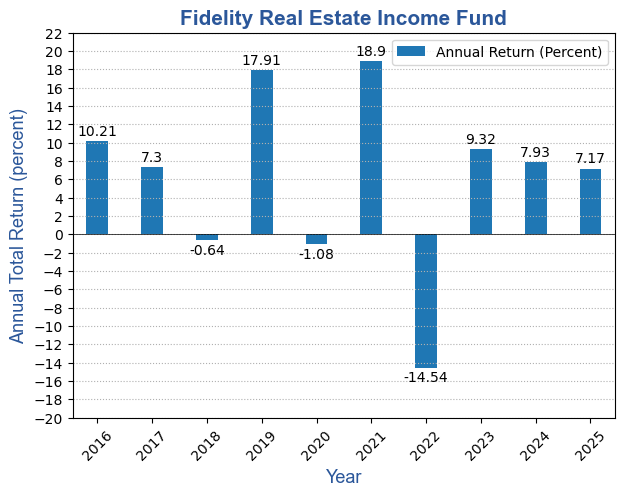

In [10]:
# Create a bar chart with Year on x axis and Annual Return on y axis
ax = annualReturnFactsForFidelity.plot(x='Year', y='Annual Return (Percent)', kind='bar', figsize=(7,5),  width=0.4)
plt.axhline(y=0, color='black', linewidth=0.5, zorder=5)
# Set title and labels for x & y axes
plt.title('Fidelity Real Estate Income Fund',fontsize=15, fontname=FONT_FAMILY, color=LABEL_COLOR, fontweight='bold')
plt.xlabel('Year', fontsize=13, fontname=FONT_FAMILY, color=LABEL_COLOR)
plt.ylabel('Annual Total Return (percent)', fontname=FONT_FAMILY, color=LABEL_COLOR, fontsize=13)
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45)
plt.yticks(np.arange(-20, 24, step=2))
# Add counts on top of bars
ax.bar_label(ax.containers[0], padding=2)
plt.grid(axis='y', linestyle=':')
# Save the bar chart as a file in images folder
plt.savefig('images/FidelityAnnualReturn.jpg', bbox_inches='tight')
plt.show()

### Filter for Annual Total Return for VANGUARD INDEX FUNDS using AnnlRtrPct tag

In [11]:
# Series S000002842 for Vanguard Growth Index Fund and Class C000007786 for ETF Shares
annualReturnVanguardFilter = (joinedFactsAndSubmissionsQ2.name == 'VANGUARD INDEX FUNDS') \
    & (joinedFactsAndSubmissionsQ2.tag == 'AnnlRtrPct') \
    & (joinedFactsAndSubmissionsQ2.series == 'S000002842') \
    & (joinedFactsAndSubmissionsQ2.otherdims == 'Class=C000007786;') 
# Display a subset of columns
annualReturnFactsForVanguard = joinedFactsAndSubmissionsQ2[annualReturnVanguardFilter][['name', 'tag', 'ddate', 'uom', 'series', 'class', 'measure', 'document', 'otherdims','value']]

annualReturnFactsForVanguard = annualReturnFactsForVanguard.reset_index(drop=True)
annualReturnFactsForVanguard

,name,tag,ddate,uom,series,class,measure,document,otherdims,value
0,VANGUARD INDEX FUNDS,AnnlRtrPct,20181231,pure,S000002842,,,ETFProspectus,Class=C000007786;,-0.0332
1,VANGUARD INDEX FUNDS,AnnlRtrPct,20191231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.3726
2,VANGUARD INDEX FUNDS,AnnlRtrPct,20201231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.4016
3,VANGUARD INDEX FUNDS,AnnlRtrPct,20211231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.2726
4,VANGUARD INDEX FUNDS,AnnlRtrPct,20221231,pure,S000002842,,,ETFProspectus,Class=C000007786;,-0.3313
5,VANGUARD INDEX FUNDS,AnnlRtrPct,20231231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.4678
6,VANGUARD INDEX FUNDS,AnnlRtrPct,20241231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.3268
7,VANGUARD INDEX FUNDS,AnnlRtrPct,20251231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.1944


### Convert Annual Return Ratio to Percentage and Create a New Column for Year & Fund Name

In [12]:
# Multiply by 100
annualReturnFactsForVanguard['Annual Return (Percent)'] = annualReturnFactsForVanguard['value'].apply(lambda x: x * 100)
# Integer Division by 10000
annualReturnFactsForVanguard['Year'] = annualReturnFactsForVanguard['ddate'].apply(lambda x: x // 10000)
annualReturnFactsForVanguard['Fund'] = 'Vanguard Growth Index Fund'
annualReturnFactsForVanguard = annualReturnFactsForVanguard.sort_values(by = ['ddate'])
annualReturnFactsForVanguard

,name,tag,ddate,uom,series,class,measure,document,otherdims,value,Annual Return (Percent),Year,Fund
0,VANGUARD INDEX FUNDS,AnnlRtrPct,20181231,pure,S000002842,,,ETFProspectus,Class=C000007786;,-0.0332,-3.3200,2018,Vanguard Growth Index Fund
1,VANGUARD INDEX FUNDS,AnnlRtrPct,20191231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.3726,37.2600,2019,Vanguard Growth Index Fund
2,VANGUARD INDEX FUNDS,AnnlRtrPct,20201231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.4016,40.1600,2020,Vanguard Growth Index Fund
3,VANGUARD INDEX FUNDS,AnnlRtrPct,20211231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.2726,27.2600,2021,Vanguard Growth Index Fund
4,VANGUARD INDEX FUNDS,AnnlRtrPct,20221231,pure,S000002842,,,ETFProspectus,Class=C000007786;,-0.3313,-33.1300,2022,Vanguard Growth Index Fund
5,VANGUARD INDEX FUNDS,AnnlRtrPct,20231231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.4678,46.7800,2023,Vanguard Growth Index Fund
6,VANGUARD INDEX FUNDS,AnnlRtrPct,20241231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.3268,32.6800,2024,Vanguard Growth Index Fund
7,VANGUARD INDEX FUNDS,AnnlRtrPct,20251231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.1944,19.4400,2025,Vanguard Growth Index Fund


### Create a Bar Chart for Annual Total Return of Vanguard Growth Index Fund

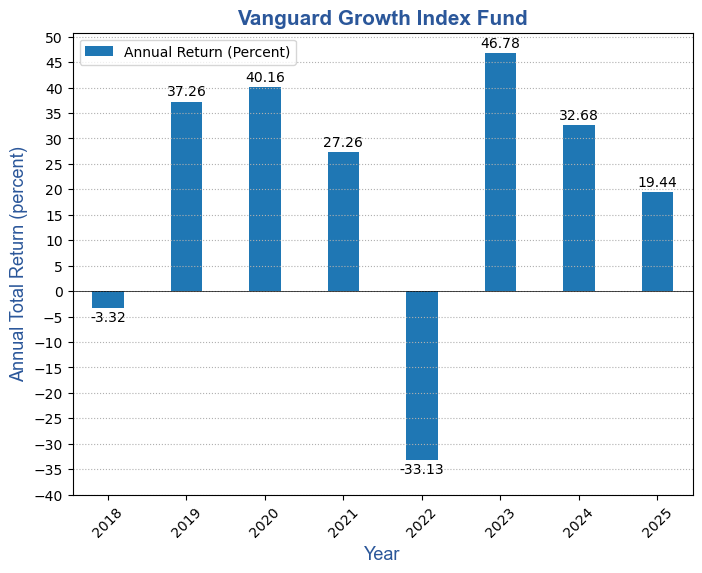

In [13]:
# Create a bar chart with Year on x axis and Annual Return on y axis
ax = annualReturnFactsForVanguard.plot(x='Year', y='Annual Return (Percent)', kind='bar', figsize=(8,6),  width=0.4)
plt.axhline(y=0, color='black', linewidth=0.5, zorder=5)
# Set title and labels for x & y axes
plt.title('Vanguard Growth Index Fund',fontsize=15, fontname=FONT_FAMILY, color=LABEL_COLOR, fontweight='bold')
plt.xlabel('Year', fontsize=13, fontname=FONT_FAMILY, color=LABEL_COLOR)
plt.ylabel('Annual Total Return (percent)', fontsize=13, fontname=FONT_FAMILY, color=LABEL_COLOR)
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45)
plt.yticks(np.arange(-40, 55, step=5))
# Add counts on top of bars
ax.bar_label(ax.containers[0], padding=2)
plt.grid(axis='y', linestyle=':')
# Save the bar chart as a file in images folder
plt.savefig('images/VanguardAnnualReturn.jpg')
plt.show()

### Append Vanguard's Annual Returns DataFrame to Fidelity's Annual Returns DataFrame

In [14]:
annualReturnFacts = pd.concat([annualReturnFactsForFidelity, annualReturnFactsForVanguard]).sort_values(by = ['ddate', 'name']).reset_index(drop=True)
annualReturnFacts = annualReturnFacts[annualReturnFacts.Year > 2017]
annualReturnFacts

,name,tag,ddate,uom,series,class,measure,document,otherdims,value,Annual Return (Percent),Year,Fund
2,FIDELITY SECURITIES FUND,AnnlRtrPct,20181231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.0064,-0.6400,2018,Fidelity Real Estate Income Fund
3,VANGUARD INDEX FUNDS,AnnlRtrPct,20181231,pure,S000002842,,,ETFProspectus,Class=C000007786;,-0.0332,-3.3200,2018,Vanguard Growth Index Fund
4,FIDELITY SECURITIES FUND,AnnlRtrPct,20191231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.1791,17.9100,2019,Fidelity Real Estate Income Fund
5,VANGUARD INDEX FUNDS,AnnlRtrPct,20191231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.3726,37.2600,2019,Vanguard Growth Index Fund
6,FIDELITY SECURITIES FUND,AnnlRtrPct,20201231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.0108,-1.0800,2020,Fidelity Real Estate Income Fund
7,VANGUARD INDEX FUNDS,AnnlRtrPct,20201231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.4016,40.1600,2020,Vanguard Growth Index Fund
8,FIDELITY SECURITIES FUND,AnnlRtrPct,20211231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,0.1890,18.9000,2021,Fidelity Real Estate Income Fund
9,VANGUARD INDEX FUNDS,AnnlRtrPct,20211231,pure,S000002842,,,ETFProspectus,Class=C000007786;,0.2726,27.2600,2021,Vanguard Growth Index Fund
10,FIDELITY SECURITIES FUND,AnnlRtrPct,20221231,pure,S000007192,,,FidelityRealEstateIncomeFund-ETFClassPRO,Class=C000276225;,-0.1454,-14.5400,2022,Fidelity Real Estate Income Fund
11,VANGUARD INDEX FUNDS,AnnlRtrPct,20221231,pure,S000002842,,,ETFProspectus,Class=C000007786;,-0.3313,-33.1300,2022,Vanguard Growth Index Fund


### Visualize Total Annual Returns for Both Funds

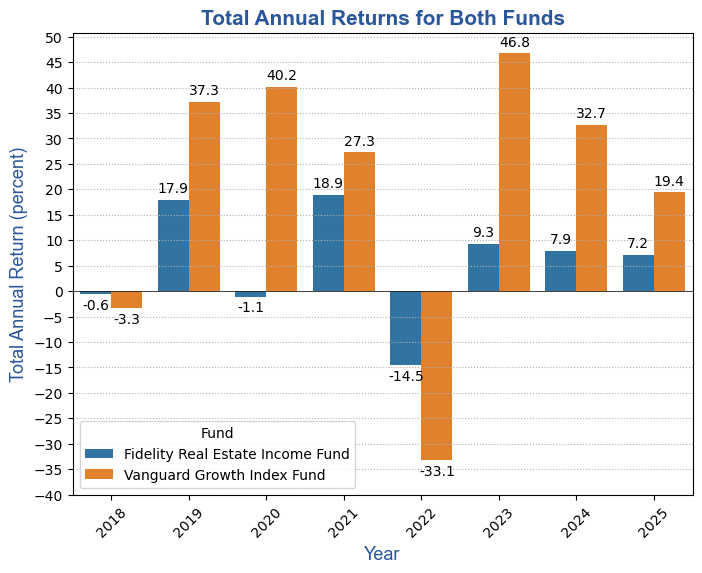

In [15]:
plt.figure(figsize=(8,6))
# Create a bar chart with Year on x axis and Annual Return on y axis. The hue parameter is set to filer name for color encoding
ax = sns.barplot(x="Year", y="Annual Return (Percent)", hue="Fund", data=annualReturnFacts)
# Add numbers on each bar
for container in ax.containers:
    ax.bar_label(container, padding=3, fmt='%.1f', fontsize=10)
    
plt.axhline(y=0, color='black', linewidth=0.5, zorder=5)

# Set title and labels for x & y axes
plt.title('Total Annual Returns for Both Funds',fontsize=15, fontname=FONT_FAMILY, color=LABEL_COLOR, fontweight='bold')
plt.xlabel('Year', fontsize=13, fontname=FONT_FAMILY, color=LABEL_COLOR)
plt.ylabel('Total Annual Return (percent)', fontsize=13, fontname=FONT_FAMILY, color=LABEL_COLOR)
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45)
plt.yticks(np.arange(-40, 55, step=5))
plt.grid(axis='y', linestyle=':')

# Save the bar chart as a file in images folder
plt.savefig('images/AnnualReturnBenchmarking.jpg')
plt.show()